<a href="https://colab.research.google.com/github/silvatria/254107023001-mobile-course/blob/main/Week7_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
#Library yang digunakan
import cv2 as cv
from google.colab.patches import cv2_imshow
import numpy as np
import math
import pandas as pd
import matplotlib.pyplot as plt
from collections import deque
from scipy import ndimage as ndi
from skimage import data, filters, color, segmentation, feature, morphology
from skimage.filters import gaussian
from skimage.segmentation import flood

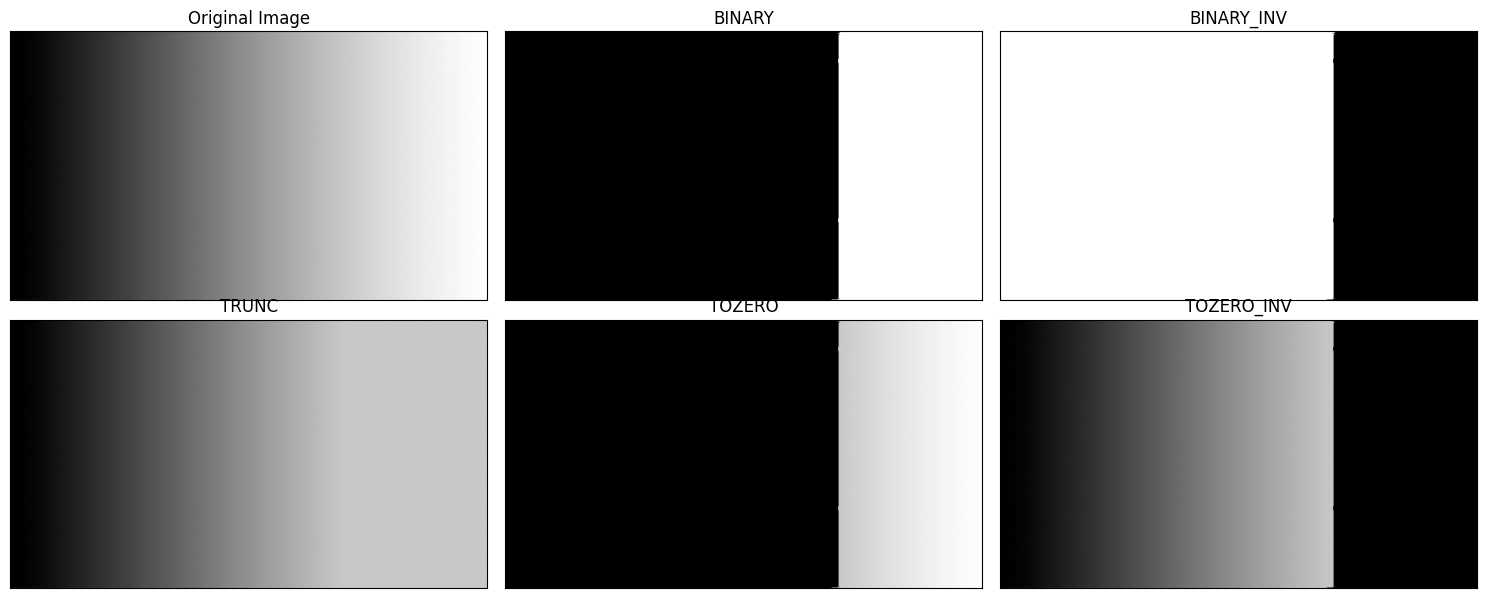

In [ ]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

# 1. Baca citra gradien dalam bentuk grayscale
filename = '/content/drive/MyDrive/2C/PCVK/Images/gradient.jpg'
img = cv.imread(filename, 0)

# Pastikan citra berhasil dibaca
if img is None:
    # Buat citra gradien dummy jika file di Drive belum ada
    img = np.tile(np.linspace(0, 255, 300, dtype=np.uint8), (150, 1))

thresh = 200
maxval = 255

# 2. Implementasi Manual Global Thresholding menggunakan NumPy
# BINARY: > thresh -> maxval, lainnya -> 0
bin_img = np.zeros_like(img)
bin_img[img > thresh] = maxval

# BINARY_INV: > thresh -> 0, lainnya -> maxval
bin_inv_img = np.zeros_like(img)
bin_inv_img[img <= thresh] = maxval

# TRUNC: > thresh -> thresh, lainnya -> nilai asli tetap
trunc_img = img.copy()
trunc_img[img > thresh] = thresh

tozero_img = np.zeros_like(img)
tozero_img[img > thresh] = img[img > thresh]

# TOZERO_INV: > thresh -> 0, lainnya -> nilai asli tetap
tozero_inv_img = img.copy()
tozero_inv_img[img > thresh] = 0

# 3. Plotting hasil sesuai layout modul
titles = ['Original Image', 'BINARY', 'BINARY_INV', 'TRUNC', 'TOZERO', 'TOZERO_INV']
images = [img, bin_img, bin_inv_img, trunc_img, tozero_img, tozero_inv_img]

plt.figure(figsize=(15, 6))
for i in range(len(images)):
    plt.subplot(2, 3, i + 1)
    plt.imshow(images[i], 'gray', vmin=0, vmax=255)
    plt.title(titles[i])
    plt.xticks([]), plt.yticks([])

plt.tight_layout()
plt.show()

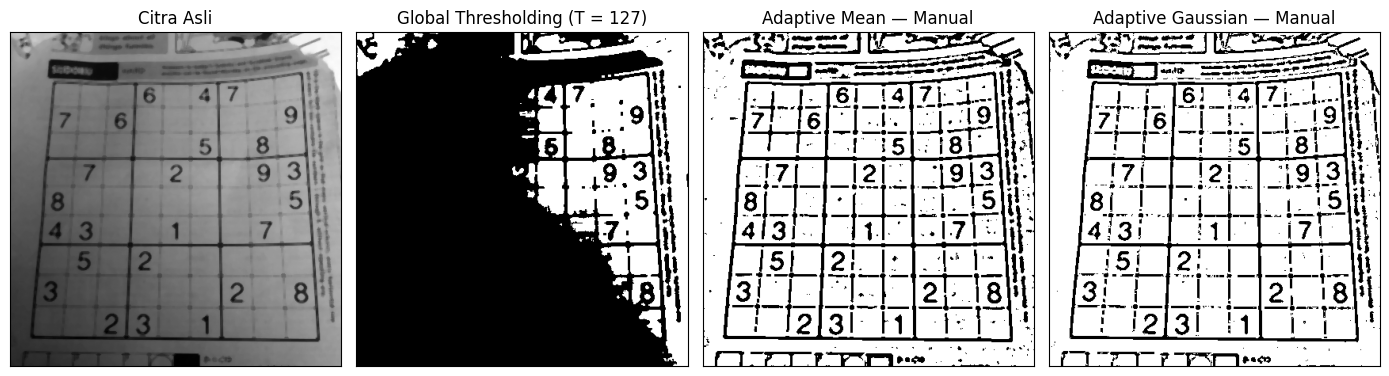

In [ ]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

# 1. Baca citra Sudoku dan ubah ke grayscale (dengan median blur opsional untuk mengurangi noise)
filename = '/content/drive/MyDrive/2C/PCVK/Images/sudoku-original.jpg'
img = cv.imread(filename, 0)
if img is None:
    # Fallback dummy image jika path file berbeda
    img = np.random.randint(100, 250, (300, 300), dtype=np.uint8)

gray = cv.medianBlur(img, 5) if img.shape[0] > 10 else img
H, W = gray.shape

# 2. Global Thresholding Manual (T = 127)
global_thresh = 127
global_img = np.zeros_like(gray)
global_img[gray > global_thresh] = 255

# 3. Fungsi Bantuan untuk Padding Citra (agar ukuran jendela pas di tepi)
block_size = 11
offset = block_size // 2
padded_img = np.pad(gray.astype(np.float32), offset, mode='reflect')

# 4. Adaptive Mean Manual
mean_img = np.zeros_like(gray)
for i in range(H):
    for j in range(W):
        # Ambil jendela lokal 11x11
        window = padded_img[i:i+block_size, j:j+block_size]
        local_mean = np.mean(window)
        # Threshold lokal dengan C = 2
        if gray[i, j] > (local_mean - 2):
            mean_img[i, j] = 255
        else:
            mean_img[i, j] = 0

# 5. Adaptive Gaussian Manual (Membuat Kernel Gaussian 11x11 dengan sigma = 2)
sigma = 2
ax = np.arange(-offset, offset + 1.0)
xx, yy = np.meshgrid(ax, ax)
kernel = np.exp(-(xx**2 + yy**2) / (2.0 * sigma**2))
kernel = kernel / np.sum(kernel) # Normalisasi kernel

gaussian_img = np.zeros_like(gray)
for i in range(H):
    for j in range(W):
        window = padded_img[i:i+block_size, j:j+block_size]
        local_gaussian_mean = np.sum(window * kernel)
        # Threshold lokal dengan C = 2
        if gray[i, j] > (local_gaussian_mean - 2):
            gaussian_img[i, j] = 255
        else:
            gaussian_img[i, j] = 0

# 6. Plotting Hasil Sesuai Layout Modul
titles = [
    'Citra Asli',
    'Global Thresholding (T = 127)',
    'Adaptive Mean — Manual',
    'Adaptive Gaussian — Manual'
]
images = [gray, global_img, mean_img, gaussian_img]

plt.figure(figsize=(14, 5))
for k in range(len(images)):
    plt.subplot(1, 4, k + 1)
    plt.imshow(images[k], 'gray')
    plt.title(titles[k])
    plt.xticks([]), plt.yticks([])

plt.tight_layout()
plt.show()

166


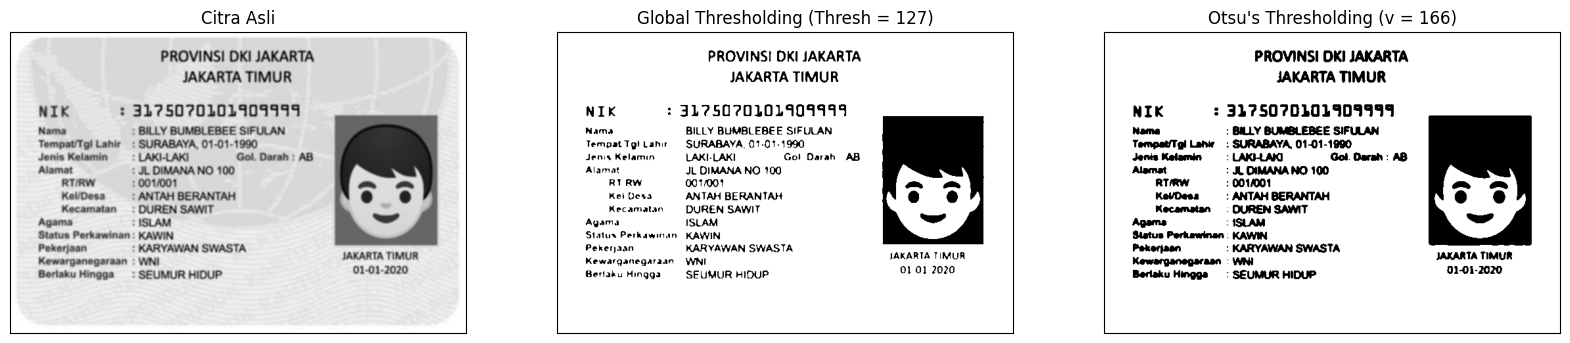

In [ ]:
filename = ('/content/drive/MyDrive/2C//PCVK/Images/ktp1.jpg')
img = cv.imread(filename, 0)
blur = cv.GaussianBlur(img, (5,5), 0)
thresh = 127

def otsu(gray):
    pixel_number = gray.shape[0] * gray.shape[1]
    mean_weight = 1.0 / pixel_number
    his, bins = np.histogram(gray, np.arange(0,257))
    final_thresh = -1
    final_value = -1
    intensity_arr = np.arange(256)
    for t in bins[1:-1]:
        pcb = np.sum(his[:t])
        pcf = np.sum(his[t:])
        if pcb == 0 or pcf == 0:
            continue
        Wb = pcb * mean_weight
        Wf = pcf * mean_weight
        mub = np.sum(intensity_arr[:t]*his[:t]) / float(pcb)
        muf = np.sum(intensity_arr[t:]*his[t:]) / float(pcf)
        value = Wb * Wf * (mub - muf)**2
        if value > final_value:
            final_value = value
            final_thresh = t
    final_img = gray.copy()
    print(final_thresh)
    final_img[gray > final_thresh] = 255
    final_img[gray <= final_thresh] = 0
    return final_img, final_thresh

otsu_biner, otsu_thresh = otsu(blur)
x = ("Otsu's Thresholding (v = ") + str(otsu_thresh) + ")"
ret, th1 = cv.threshold(blur, thresh, 255, cv.THRESH_BINARY)
titles = ['Citra Asli', 'Global Thresholding (Thresh = ' + str(thresh) + ')', x]
citra3 = [blur, th1, otsu_biner]

plt.figure(figsize=(20,15))
for i in range(len(citra3)):
    plt.subplot(1,3,i+1), plt.imshow(citra3[i], 'gray')
    plt.title(titles[i])
    plt.xticks([]), plt.yticks([])
plt.show()

*** Seed (baris, kolom): (36, 43) | intensitas: 159.000000
Toleransi 5: 21 piksel
Toleransi 20: 919 piksel
Toleransi 60: 15253 piksel


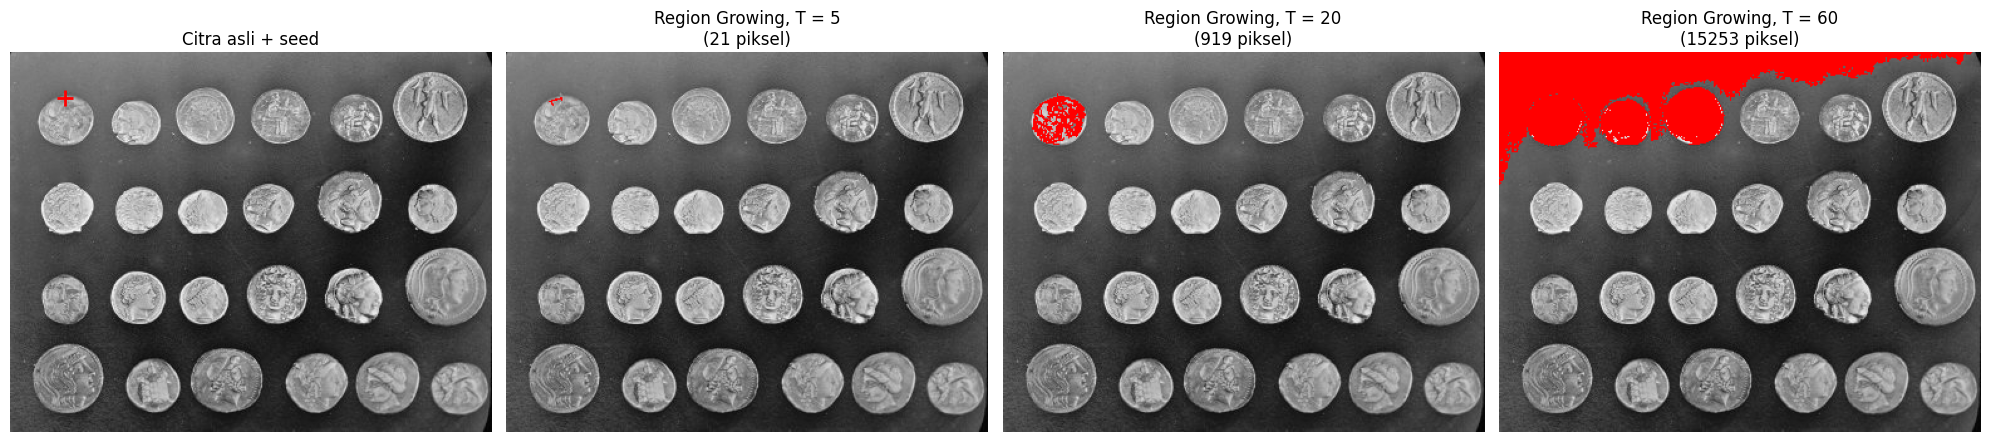

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data
from skimage.segmentation import flood

# 1. Load citra koin
gray = data.coins()

# 2. Tentukan seed (baris, kolom) sesuai output target
seed = (36, 43)
intensity = float(gray[seed[0], seed[1]])
tolerances = [5, 20, 60]

# 3. Cetak teks informasi seed dan jumlah piksel persis seperti di modul
print(f"*** Seed (baris, kolom): {seed} | intensitas: {intensity:.6f}")

pixel_counts = []
for T in tolerances:
    mask = flood(gray, seed_point=seed, tolerance=T, connectivity=1)
    pc = np.sum(mask)
    pixel_counts.append(pc)
    print(f"Toleransi {T}: {pc} piksel")

# 4. Plotting sejajar (1 baris, 4 kolom)
plt.figure(figsize=(20, 5))

# Kolom 1: Citra asli + seed (tanda tambah merah)
plt.subplot(1, 4, 1)
plt.imshow(gray, cmap='gray')
plt.plot(seed[1], seed[0], 'r+', markersize=12, markeredgewidth=2)
plt.title("Citra asli + seed")
plt.axis('off')

# Kolom 2, 3, 4: Hasil flood dengan toleransi 5, 20, 60
for i, T in enumerate(tolerances):
    mask = flood(gray, seed_point=seed, tolerance=T, connectivity=1)

    # Buat citra RGB untuk overlay merah
    rgb_img = np.stack([gray, gray, gray], axis=-1)
    rgb_img[mask] = [255, 0, 0] # Warna merah

    plt.subplot(1, 4, i + 2)
    plt.imshow(rgb_img)
    plt.title(f"Region Growing, T = {T}\n({pixel_counts[i]} piksel)")
    plt.axis('off')

plt.tight_layout()
plt.show()

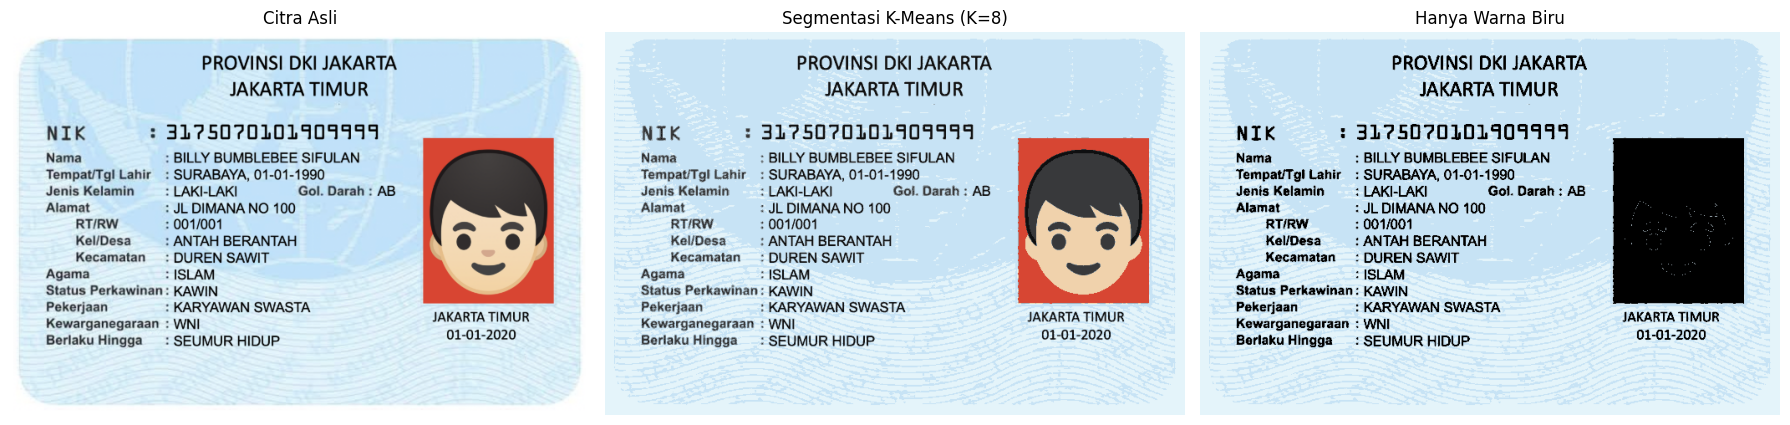

In [ ]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

# 1. Baca citra KTP dan ubah ke RGB
filename = '/content/drive/MyDrive/2C//PCVK/Images/ktp1.jpg'
img = cv.imread(filename)
img_rgb = cv.cvtColor(img, cv.COLOR_BGR2RGB)

# 2. Segmentasi K-Means (K = 8) sesuai modul
Z = img_rgb.reshape((-1, 3))
Z = np.float32(Z)

k = 8
criteria = (cv.TERM_CRITERIA_EPS + cv.TERM_CRITERIA_MAX_ITER, 10, 1.0)
ret, label, center = cv.kmeans(Z, k, None, criteria, 10, cv.KMEANS_RANDOM_CENTERS)
center = np.uint8(center)
segmented_data = center[label.flatten()]
segmented_img = segmented_data.reshape(img_rgb.shape)

# 3. Konversi ke HSV untuk menyaring warna latar belakang biru KTP secara spesifik
hsv_img = cv.cvtColor(segmented_img, cv.COLOR_RGB2HSV)
H = hsv_img[:, :, 0]
S = hsv_img[:, :, 1]
V = hsv_img[:, :, 2]

# Perbaikan rentang HSV untuk warna latar belakang biru muda KTP (menghindari garis hitam)
# Di OpenCV, Hue biru muda/sian berada di sekitar 90-110, dengan saturasi tidak terlalu tinggi
mask = (H >= 90) & (H <= 115) & (S >= 15) & (S <= 120) & (V >= 180)

# 4. Buat citra akhir: Hanya tampilkan area biru KTP, sisanya hitam
hanya_biru = np.zeros_like(segmented_img)
hanya_biru[mask] = segmented_img[mask]

# 5. Plotting perbandingan 3 gambar
titles = ['Citra Asli', 'Segmentasi K-Means (K=8)', 'Hanya Warna Biru']
images = [img_rgb, segmented_img, hanya_biru]

plt.figure(figsize=(18, 6))
for i in range(3):
    plt.subplot(1, 3, i + 1)
    plt.imshow(images[i])
    plt.title(titles[i])
    plt.axis('off')

plt.tight_layout()
plt.show()

In [ ]:
!apt-get -qq update
!apt-get -qq install tesseract-ocr tesseract-ocr-ind
!pip -q install pytesseract

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package tesseract-ocr-ind.
(Reading database ... 122815 files and directories currently installed.)
Preparing to unpack .../tesseract-ocr-ind_1%3a4.1.0-2_all.deb ...
Unpacking tesseract-ocr-ind (1:4.1.0-2) ...
Setting up tesseract-ocr-ind (1:4.1.0-2) ...


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
SUKSES: Gambar KTP berhasil dimuat dari /content/drive/MyDrive/2C/PCVK/Images/ktp1.jpg

=== TIGA CITRA UNTUK DIBANDINGKAN ===


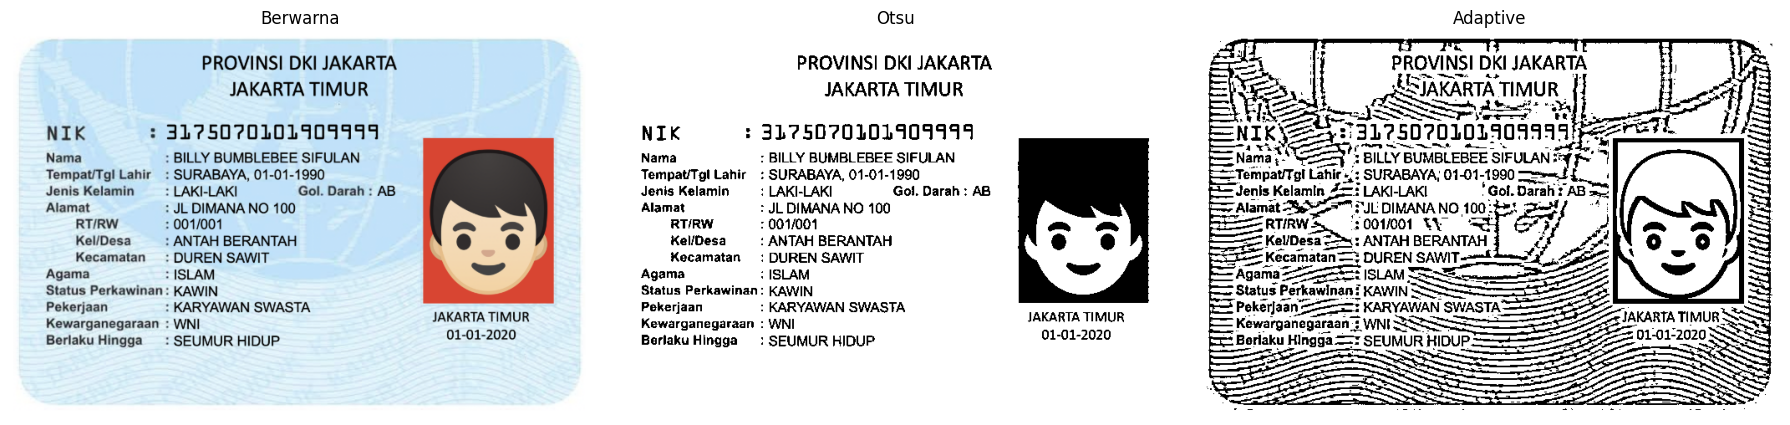

=== HASIL PEMBACAAN TEKS (Area Teks Berkotak Hijau) ===


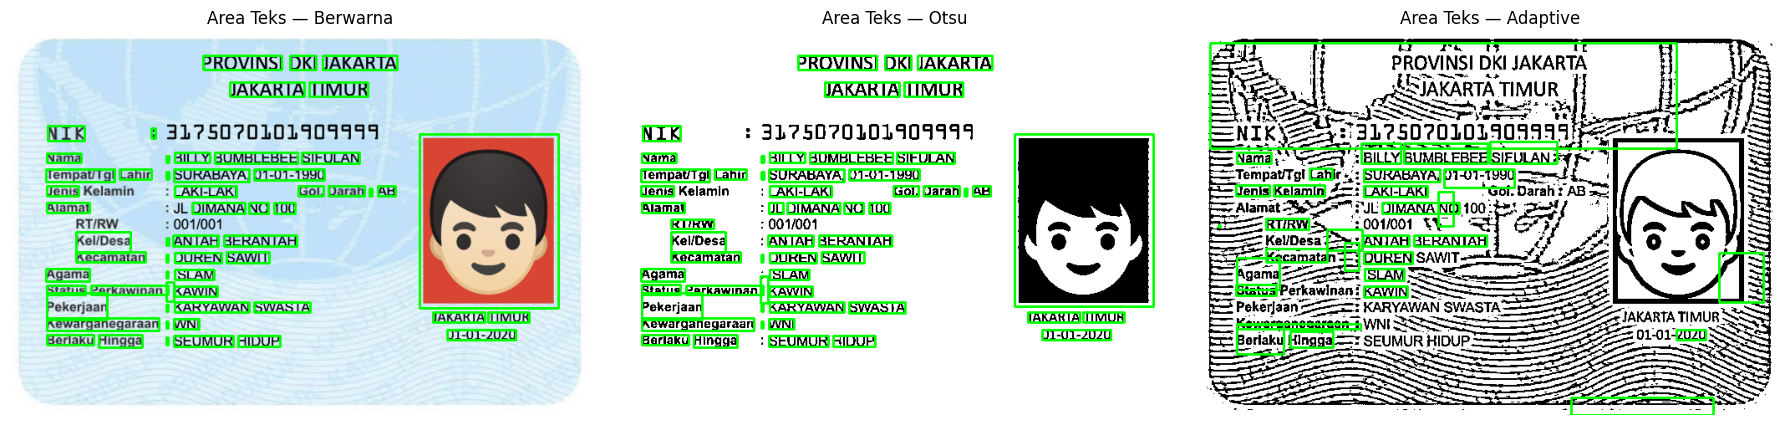


--- TEKS OCR: BERWARNA ---
PROVINSI DKI JAKARTA

JAKARTA TIMUR
NIK 1 31?50?0101409119
Nama : BILLY BUMBLEBEE SIFULAN
Tempat/Tgl Lahir : SURABAYA, 01-01-1990
Jenis Kelamin: LAKI-LAKI Gol. Darah : AB
Alamat JL DIMANA NO 100

RT/RW :001/001
Kel/Desa : ANTAH BERANTAH
Kecamatan : DUREN SAWIT

Agama : ISLAM
Status Perkawinan : KAWIN
Pekerjaan : KARYAWAN SWASTA

JAKARTA TIMUR
Berlaku Hingga — : SEUMUR HIDUP 01-01-2020

Kewarganegaraan : WNI


--- TEKS OCR: OTSU ---
PROVINSI DKI JAKARTA

JAKARTA TIMUR
NIK 1 3125D20101409119
Nama : BILLY BUMBLEBEE SIFULAN
Tempat/Tgl Lahir : SURABAYA, 01-01-1990
Jenis Kelamin: LAKI-LAKI Gol. Darah : AB
Alamat : JL DIMANA NO 100

RT/RW 1001/001
Kel/Desa ! ANTAH BERANTAH
Kecamatan : DUREN SAWIT

Agama : ISLAM
Status Perkawinan : KAWIN
Pekerjaan : KARYAWAN SWASTA

JAKARTA TIMUR
Berlaku Hingga — : SEUMUR HIDUP 01-01-2020

Kewarganegaraan : WNI


--- TEKS OCR: ADAPTIVE ---
Nama MA 3 BILLY BUMBLEBEE SIFULAN 7
ETempat/TgI Lahir -/3 SURABAYA, 01-01-1990 2
Jenis Kelamin

In [ ]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
import pytesseract
import os

# 3. Baca citra KTP
filename = '/content/drive/MyDrive/2C/PCVK/Images/ktp1.jpg'
img_color = cv.imread(filename)

if img_color is None:
    print(f"PERINGATAN: File '{filename}' tidak ditemukan! Coba cek ulang foldernya.")
    # Buat citra dummy putih kalau beneran gak ketemu supaya kodenya gak error
    img_color = np.ones((400, 600, 3), dtype=np.uint8) * 255
else:
    print(f"SUKSES: Gambar KTP berhasil dimuat dari {filename}")

img_rgb = cv.cvtColor(img_color, cv.COLOR_BGR2RGB)
img_gray = cv.cvtColor(img_color, cv.COLOR_BGR2GRAY)

# 4. Proses Otsu & Adaptive Thresholding
_, img_otsu = cv.threshold(img_gray, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)
img_adaptive = cv.adaptiveThreshold(
    img_gray, 255, cv.ADAPTIVE_THRESH_MEAN_C,
    cv.THRESH_BINARY, 11, 2
)

# Konversi otsu dan adaptive ke 3 channel (RGB) agar kotak hijaunya berwarna
img_otsu_rgb = cv.cvtColor(img_otsu, cv.COLOR_GRAY2RGB)
img_adaptive_rgb = cv.cvtColor(img_adaptive, cv.COLOR_GRAY2RGB)

sources = [
    ('Berwarna', img_rgb),
    ('Otsu', img_otsu_rgb),
    ('Adaptive', img_adaptive_rgb)
]

# Ubah PSM ke 3 agar layout KTP terbaca optimal oleh Tesseract
custom_config = r'-l ind --psm 3'

# --- BARIS 1: TIGA CITRA UNTUK DIBANDINGKAN ---
print("\n=== TIGA CITRA UNTUK DIBANDINGKAN ===")
plt.figure(figsize=(18, 5))
for i, (title, img) in enumerate(sources):
    plt.subplot(1, 3, i + 1)
    plt.imshow(img)
    plt.title(title)
    plt.axis('off')
plt.tight_layout()
plt.show()

# --- BARIS 2: HASIL PEMBACAAN TEKS (KOTAK HIJAU) ---
print("=== HASIL PEMBACAAN TEKS (Area Teks Berkotak Hijau) ===")
plt.figure(figsize=(18, 5))
for i, (title, img) in enumerate(sources):
    img_box = img.copy()

    # Ekstraksi data bounding box OCR dengan confidence > 60
    data = pytesseract.image_to_data(img, config=custom_config, output_type=pytesseract.Output.DICT)
    n_boxes = len(data['text'])

    for j in range(n_boxes):
        conf = int(data['conf'][j])
        if conf > 60:
            (x, y, w, h) = (data['left'][j], data['top'][j], data['width'][j], data['height'][j])
            img_box = cv.rectangle(img_box, (x, y), (x + w, y + h), (0, 255, 0), 2)

    plt.subplot(1, 3, i + 1)
    plt.imshow(img_box)
    plt.title(f"Area Teks — {title}")
    plt.axis('off')
plt.tight_layout()
plt.show()

# --- CETAK TEKS HASIL OCR KE KONSOL ---
for title, img in sources:
    print(f"\n--- TEKS OCR: {title.upper()} ---")
    text = pytesseract.image_to_string(img, config=custom_config)
    print(text if text.strip() else "[Teks tidak terbaca, pastikan path gambar benar]")